In [ ]:
!pip install kagglehub --quiet

import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

In [ ]:
import os
import numpy as np
import tensorflow as tf
import kagglehub
import matplotlib.pyplot as plt

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)


In [ ]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset Path:", path)

base_dir = os.path.join(path, "chest_xray")
train_dir = os.path.join(base_dir, "train")
test_dir  = os.path.join(base_dir, "test")
print(base_dir)

In [ ]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.15,
    height_shift_range=0.15,
    zoom_range=0.15,
    shear_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest',
    validation_split=0.20
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    subset="training",
    shuffle=True,
    seed=SEED
)

val_gen = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    subset="validation",
    shuffle=False,
    seed=SEED
)

test_gen = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    color_mode="rgb",
    shuffle=False
)

print("Class indices:", train_gen.class_indices)

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.
Found 624 images belonging to 2 classes.
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:

y_train = train_gen.classes
classes = np.unique(y_train)

weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {0: 1.9445479962721341, 1: 0.6730645161290323}


In [ ]:

base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:

callbacks = [
    EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    ModelCheckpoint("best_vgg16.keras", monitor="val_auc", mode="max", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

In [ ]:

base_model.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("\n================ Phase 1: Feature Extraction ================")
history1 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)



================ Phase 1: Feature Extraction ================


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 942ms/step - accuracy: 0.6422 - auc: 0.7305 - loss: 0.6778 - precision: 0.8646 - recall: 0.6203
Epoch 1: val_auc improved from -inf to 0.95286, saving model to best_vgg16.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.6427 - auc: 0.7312 - loss: 0.6769 - precision: 0.8650 - recall: 0.6207 - val_accuracy: 0.8466 - val_auc: 0.9529 - val_loss: 0.5331 - val_precision: 0.8413 - val_recall: 0.9781 - learning_rate: 1.0000e-04
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 700ms/step - accuracy: 0.7786 - auc: 0.8997 - loss: 0.4496 - precision: 0.9589 - recall: 0.7348
Epoch 2: val_auc improved from 0.95286 to 0.96399, saving model to best_vgg16.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 115s 880ms/step - accuracy: 0.7787 - auc: 0.8997 - loss: 0.4495 - precision: 0.9589 - recall: 0.7349 - val_accuracy: 0.9080 - val_auc: 0.9640 - val_loss: 0.4148 - val_precision: 0.9314 - val_recall: 0.9458 - learning_rate: 1.0000e-04
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━

In [ ]:

base_model.trainable = True


for layer in base_model.layers[:-4]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

print("\n================ Phase 2: Fine Tuning ================")
history2 = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)


================ Phase 2: Fine Tuning ================
Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 749ms/step - accuracy: 0.8892 - auc: 0.9583 - loss: 0.2763 - precision: 0.9773 - recall: 0.8733
Epoch 1: val_auc improved from 0.98358 to 0.98885, saving model to best_vgg16.keras
131/131 ━━━━━━━━━━━━━━━━━━━━ 136s 965ms/step - accuracy: 0.8892 - auc: 0.9583 - loss: 0.2761 - precision: 0.9773 - recall: 0.8733 - val_accuracy: 0.9377 - val_auc: 0.9889 - val_loss: 0.1884 - val_precision: 0.9944 - val_recall: 0.9213 - learning_rate: 1.0000e-05
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 726ms/step - accuracy: 0.9119 - auc: 0.9745 - loss: 0.2152 - precision: 0.9813 - recall: 0.8988
Epoch 2: val_auc did not improve from 0.98885
131/131 ━━━━━━━━━━━━━━━━━━━━ 120s 915ms/step - accuracy: 0.9119 - auc: 0.9745 - loss: 0.2152 - precision: 0.9813 - recall: 0.8988 - val_accuracy: 0.9291 - val_auc: 0.9884 - val_loss: 0.2185 - val_precision: 0.9972 - val_recall: 0.9071 - learning_rate: 1.0000e-05
Epoch 3/10


================ Test Evaluation ================
20/20 ━━━━━━━━━━━━━━━━━━━━ 19s 922ms/step - accuracy: 0.9176 - auc: 0.6456 - loss: 0.2237 - precision: 0.5596 - recall: 0.6343
{'loss': 0.22831958532333374, 'compile_metrics': 0.9230769276618958}

Classification Report:

              precision    recall  f1-score   support

      NORMAL     0.9043    0.8889    0.8966       234
   PNEUMONIA     0.9340    0.9436    0.9388       390

    accuracy                         0.9231       624
   macro avg     0.9192    0.9162    0.9177       624
weighted avg     0.9229    0.9231    0.9229       624


Confusion Matrix:
 [[208  26]
 [ 22 368]]


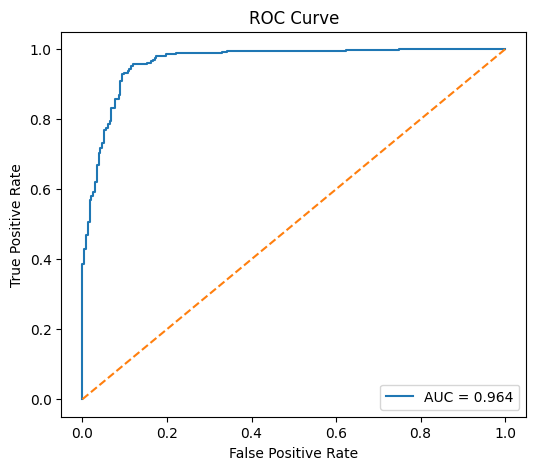


✅ Done: Model trained + evaluated correctly.


In [ ]:

print("\n================ Test Evaluation ================")
results = model.evaluate(test_gen, verbose=1)
print(dict(zip(model.metrics_names, results)))


y_true = test_gen.classes
y_prob = model.predict(test_gen, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=["NORMAL", "PNEUMONIA"], digits=4))

cm = confusion_matrix(y_true, y_pred)
print("\nConfusion Matrix:\n", cm)


fpr, tpr, _ = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0,1],[0,1],'--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

print("\n✅ Done: Model trained + evaluated correctly.")

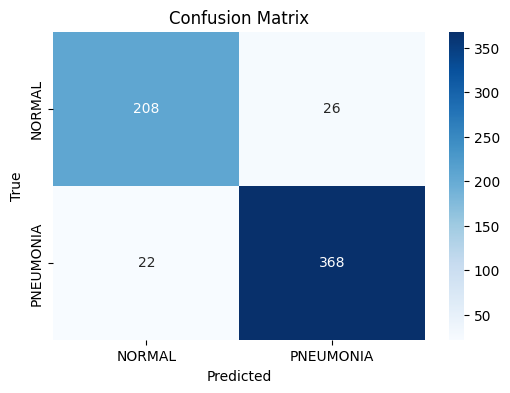

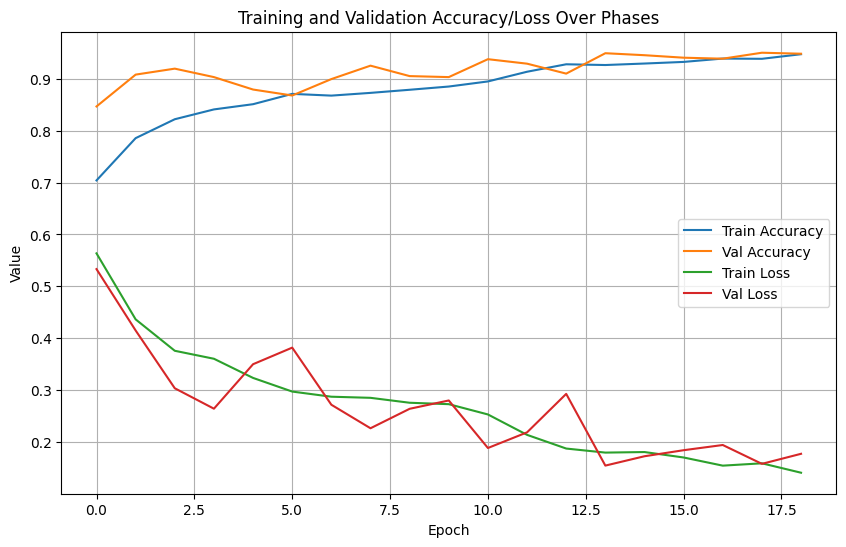

In [ ]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['NORMAL', 'PNEUMONIA'], yticklabels=['NORMAL', 'PNEUMONIA'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


history_combined = {}
for key in history1.history.keys():
    history_combined[key] = history1.history[key] + history2.history[key]

plt.figure(figsize=(10, 6))
plt.plot(history_combined['accuracy'], label='Train Accuracy')
plt.plot(history_combined['val_accuracy'], label='Val Accuracy')
plt.plot(history_combined['loss'], label='Train Loss')
plt.plot(history_combined['val_loss'], label='Val Loss')
plt.title('Training and Validation Accuracy/Loss Over Phases')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()